In [1]:

import sys
import importlib
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

project_root = Path.cwd().resolve()

if project_root.name == "notebooks":
    project_root = project_root.parent

if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

import src.sensitivity_analysis_loss_magnitude as magnitude_module

importlib.reload(magnitude_module)

results, annual_losses_by_scenario = (
    magnitude_module.run_magnitude_sensitivity(
        n_years=100_000,
        seed=20261025,
    )
)

print("Number of scenarios:", len(results))
print("Simulation years per scenario:", 100_000)


Number of scenarios: 15
Simulation years per scenario: 100000


In [ ]:

#Formatted risk comparison tables

PARAMETER_LABELS = {
    "affected_churn": "Affected-Customer Churn",
    "contribution_margin": "Contribution Margin",
    "customer_exposure": "Customer Exposure",
}


def scenario_label(parameter, value):
    if parameter == "affected_churn":
        return f"{value:.2%}"

    if parameter == "contribution_margin":
        return f"${value:,.0f}"

    return f"{value:.0%} of baseline"


DISPLAY_COLUMNS = [
    "Scenario",
    "aal_usd",
    "var_95_usd",
    "var_99_usd",
    "tvar_95_usd",
    "p_loss_gt_2m",
    "p_loss_gt_5m",
    "p_loss_gt_10m",
    "p_loss_gt_15m",
]

FORMATTERS = {
    "aal_usd": "${:,.0f}",
    "var_95_usd": "${:,.0f}",
    "var_99_usd": "${:,.0f}",
    "tvar_95_usd": "${:,.0f}",
    "p_loss_gt_2m": "{:.2%}",
    "p_loss_gt_5m": "{:.2%}",
    "p_loss_gt_10m": "{:.3%}",
    "p_loss_gt_15m": "{:.3%}",
}


for parameter, title in PARAMETER_LABELS.items():
    subset = results.loc[
        results["parameter"] == parameter
    ].copy()

    subset["Scenario"] = [
        scenario_label(parameter, value)
        for value in subset["parameter_value"]
    ]

    print(f"\n{title} Sensitivity")

    display(
        subset[DISPLAY_COLUMNS].style.format(FORMATTERS)
    )



Affected-Customer Churn Sensitivity


,Scenario,aal_usd,var_95_usd,var_99_usd,tvar_95_usd,p_loss_gt_2m,p_loss_gt_5m,p_loss_gt_10m,p_loss_gt_15m
0,0.05%,"$165,510","$986,275","$2,308,629","$1,842,681",1.36%,0.11%,0.006%,0.001%
1,0.10%,"$201,623","$1,243,045","$2,817,559","$2,241,966",2.10%,0.17%,0.011%,0.001%
2,0.20%,"$272,725","$1,730,117","$3,793,562","$3,028,009",3.99%,0.43%,0.021%,0.002%
3,0.30%,"$344,465","$2,211,778","$4,715,377","$3,817,430",5.78%,0.86%,0.055%,0.006%
4,0.50%,"$488,815","$3,166,088","$6,820,119","$5,424,247",8.84%,2.13%,0.271%,0.033%



Contribution Margin Sensitivity


,Scenario,aal_usd,var_95_usd,var_99_usd,tvar_95_usd,p_loss_gt_2m,p_loss_gt_5m,p_loss_gt_10m,p_loss_gt_15m
5,"$100,000","$181,725","$1,074,922","$2,525,912","$1,999,753",1.64%,0.14%,0.009%,0.001%
6,"$150,000","$223,089","$1,368,871","$3,083,460","$2,463,490",2.64%,0.23%,0.011%,0.001%
7,"$210,000","$272,725","$1,730,117","$3,793,562","$3,028,009",3.99%,0.43%,0.021%,0.002%
8,"$250,000","$305,816","$1,958,087","$4,286,713","$3,407,129",4.87%,0.63%,0.031%,0.002%
9,"$300,000","$347,179","$2,235,338","$4,867,571","$3,883,518",5.92%,0.93%,0.055%,0.003%



Customer Exposure Sensitivity


,Scenario,aal_usd,var_95_usd,var_99_usd,tvar_95_usd,p_loss_gt_2m,p_loss_gt_5m,p_loss_gt_10m,p_loss_gt_15m
10,50% of baseline,"$208,256","$1,289,219","$2,869,326","$2,304,984",2.26%,0.20%,0.009%,0.004%
11,75% of baseline,"$240,419","$1,520,583","$3,320,057","$2,661,192",3.13%,0.28%,0.014%,0.001%
12,100% of baseline,"$272,725","$1,730,117","$3,793,562","$3,028,009",3.99%,0.43%,0.021%,0.002%
13,125% of baseline,"$295,483","$1,903,987","$4,037,864","$3,242,934",4.65%,0.51%,0.027%,0.001%
14,150% of baseline,"$316,091","$2,055,155","$4,244,200","$3,424,210",5.21%,0.59%,0.021%,0.004%


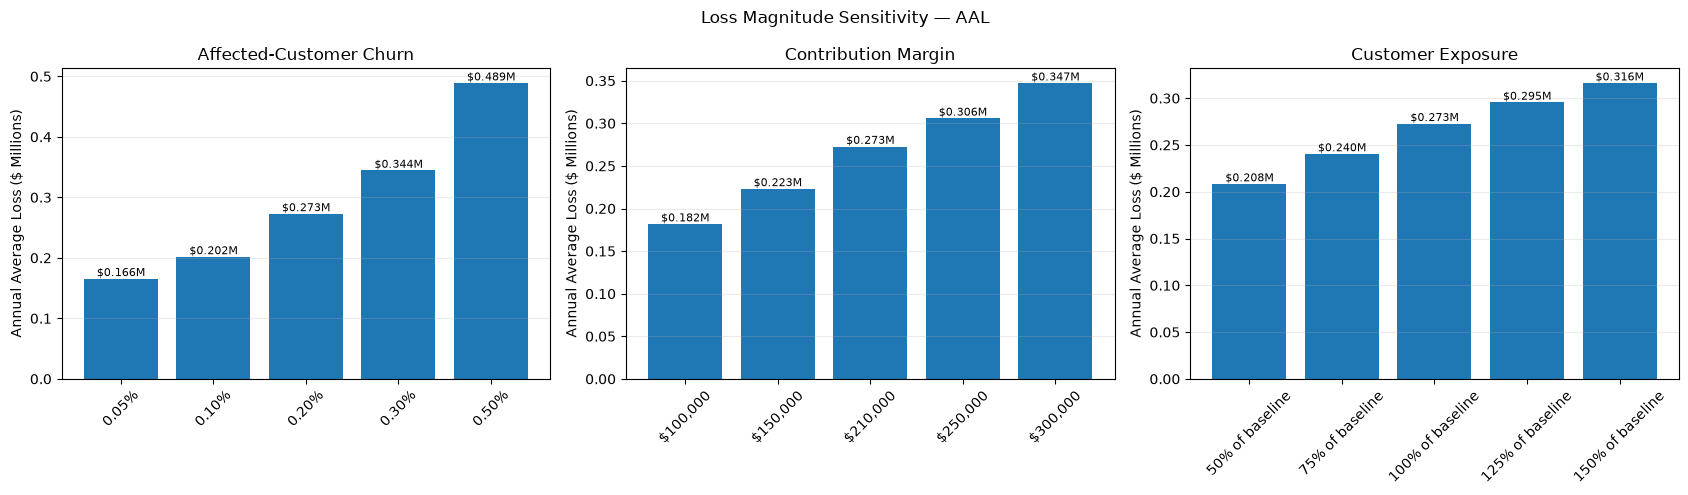

In [ ]:

#AAL comparison charts

fig, axes = plt.subplots(1, 3, figsize=(17, 5))

for ax, (parameter, title) in zip(
    axes, PARAMETER_LABELS.items()
):
    subset = results[
        results["parameter"] == parameter
    ].sort_values("parameter_value")

    labels = [
        scenario_label(parameter, v)
        for v in subset["parameter_value"]
    ]

    values = subset["aal_usd"] / 1_000_000

    bars = ax.bar(labels, values)

    ax.set_title(title)
    ax.set_ylabel("Annual Average Loss ($ Millions)")
    ax.tick_params(axis="x", rotation=45)
    ax.grid(axis="y", alpha=0.25)

    for bar, value in zip(bars, values):
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height(),
            f"${value:.3f}M",
            ha="center",
            va="bottom",
            fontsize=8,
        )

plt.suptitle("Loss Magnitude Sensitivity — AAL")
plt.tight_layout()
plt.show()


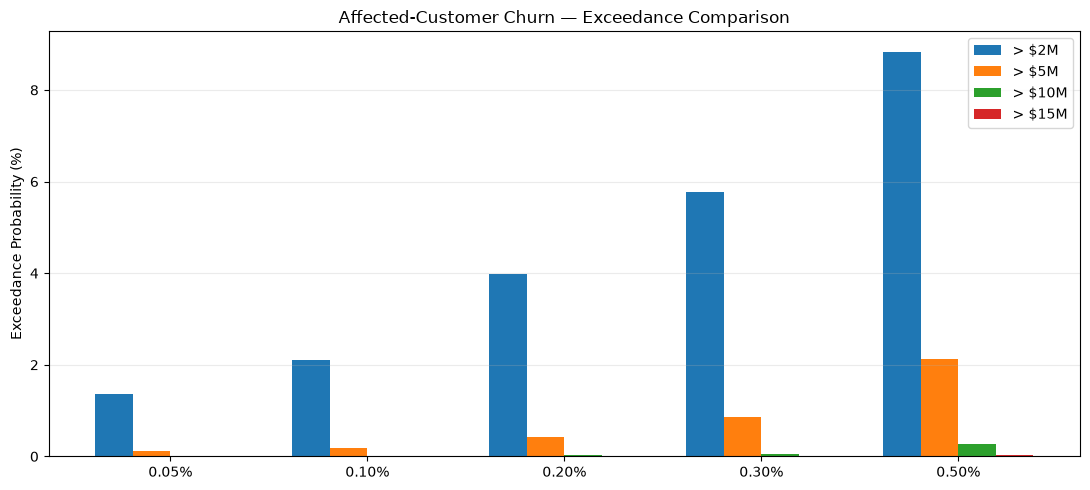

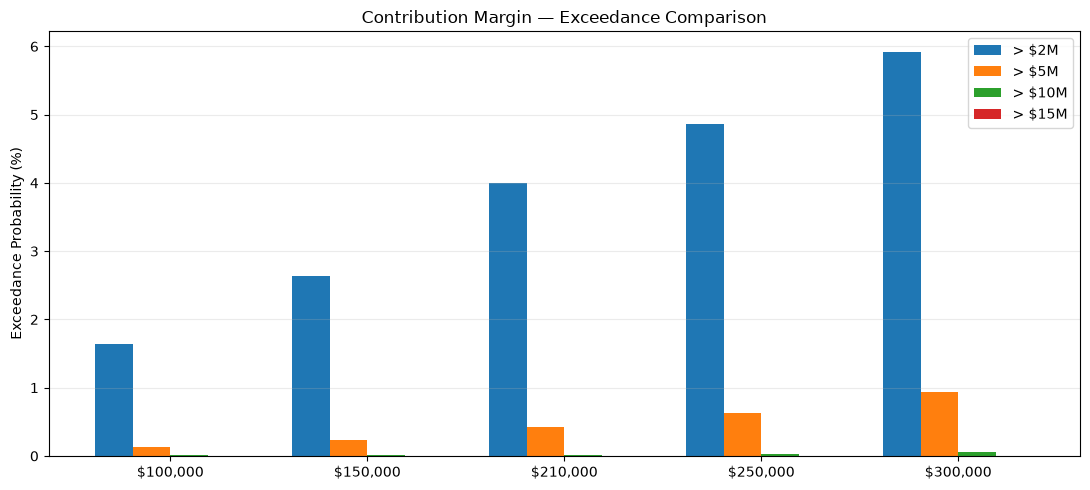

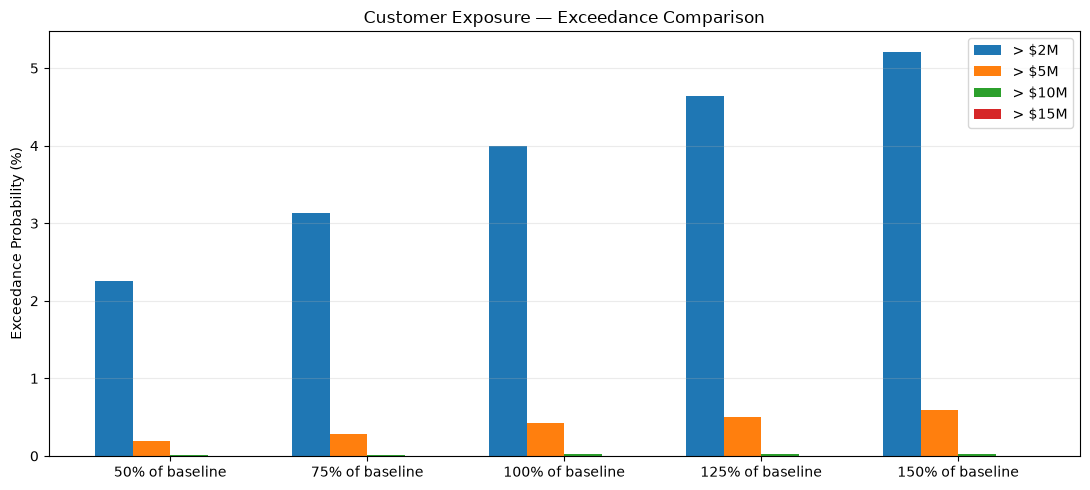

In [4]:

#Fixed-threshold exceedance comparison

THRESHOLDS_M = [2, 5, 10, 15]

for parameter, title in PARAMETER_LABELS.items():
    subset = results[
        results["parameter"] == parameter
    ].sort_values("parameter_value")

    fig, ax = plt.subplots(figsize=(11, 5))

    x = np.arange(len(subset))
    width = 0.19

    for i, threshold in enumerate(THRESHOLDS_M):
        probabilities = (
            subset[f"p_loss_gt_{threshold}m"].to_numpy() * 100
        )

        ax.bar(
            x + (i - 1.5) * width,
            probabilities,
            width=width,
            label=f"> ${threshold}M",
        )

    ax.set_xticks(x)
    ax.set_xticklabels([
        scenario_label(parameter, v)
        for v in subset["parameter_value"]
    ])

    ax.set_ylabel("Exceedance Probability (%)")
    ax.set_title(f"{title} — Exceedance Comparison")
    ax.legend()
    ax.grid(axis="y", alpha=0.25)

    plt.tight_layout()
    plt.show()


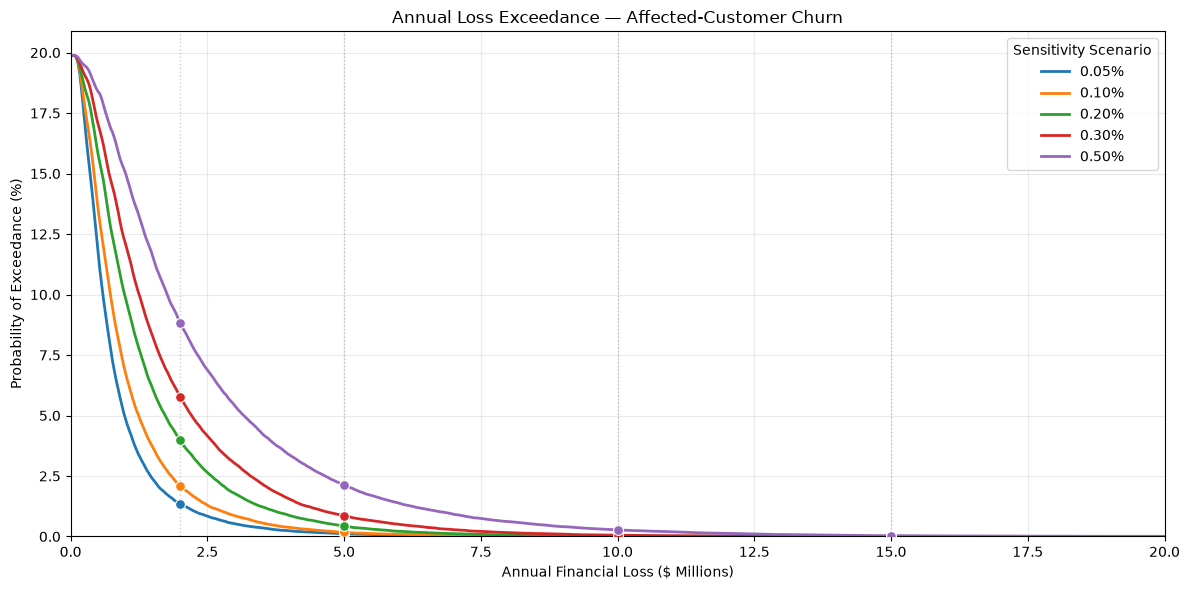


Exceedance Probabilities at Selected Annual Loss Thresholds


,Scenario,P(Loss > $2M),P(Loss > $5M),P(Loss > $10M),P(Loss > $15M)
0,0.05%,1.356%,0.114%,0.006%,0.001%
1,0.10%,2.096%,0.173%,0.011%,0.001%
2,0.20%,3.992%,0.428%,0.021%,0.002%
3,0.30%,5.782%,0.861%,0.055%,0.006%
4,0.50%,8.838%,2.127%,0.271%,0.033%


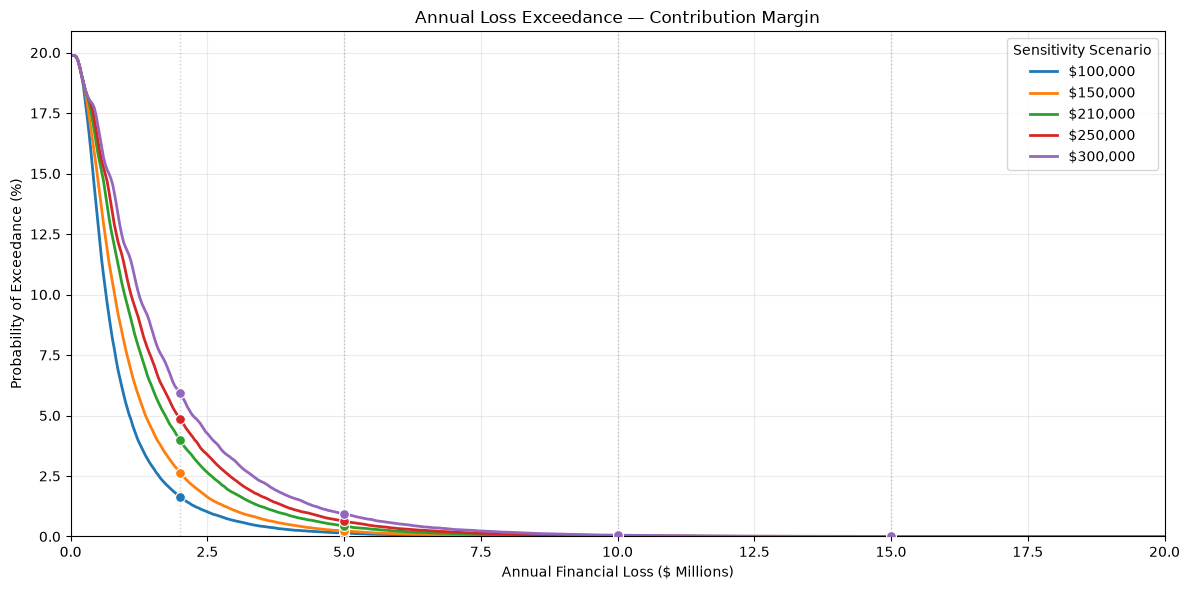


Exceedance Probabilities at Selected Annual Loss Thresholds


,Scenario,P(Loss > $2M),P(Loss > $5M),P(Loss > $10M),P(Loss > $15M)
0,"$100,000",1.641%,0.138%,0.009%,0.001%
1,"$150,000",2.637%,0.228%,0.011%,0.001%
2,"$210,000",3.992%,0.428%,0.021%,0.002%
3,"$250,000",4.868%,0.630%,0.031%,0.002%
4,"$300,000",5.924%,0.930%,0.055%,0.003%


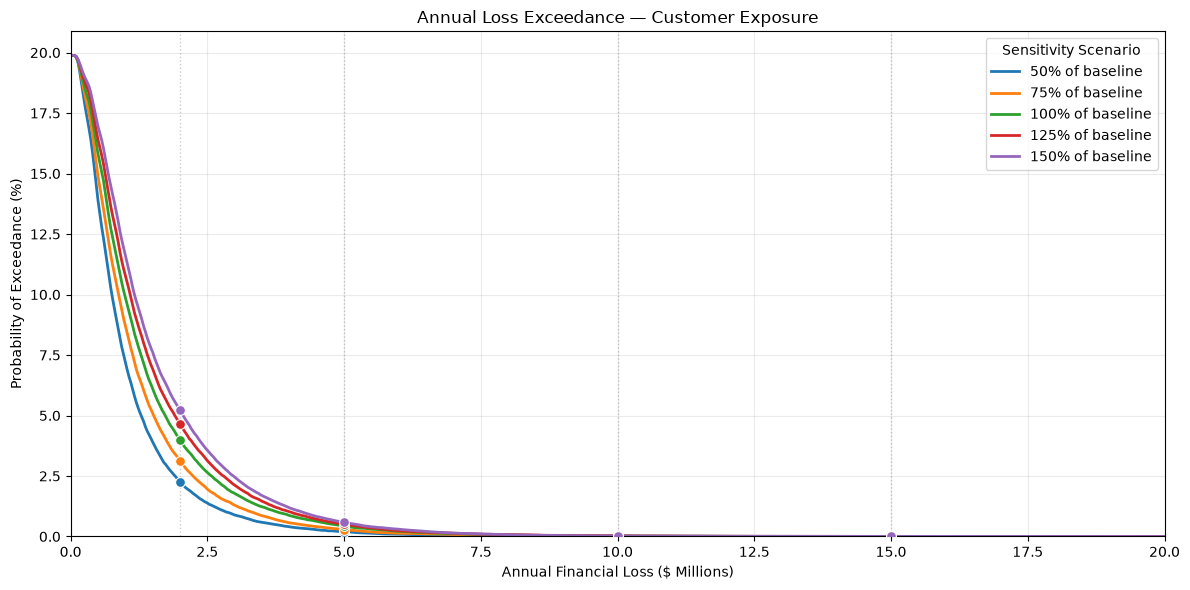


Exceedance Probabilities at Selected Annual Loss Thresholds


,Scenario,P(Loss > $2M),P(Loss > $5M),P(Loss > $10M),P(Loss > $15M)
0,50% of baseline,2.259%,0.197%,0.009%,0.004%
1,75% of baseline,3.127%,0.284%,0.014%,0.001%
2,100% of baseline,3.992%,0.428%,0.021%,0.002%
3,125% of baseline,4.646%,0.505%,0.027%,0.001%
4,150% of baseline,5.214%,0.586%,0.021%,0.004%


In [7]:
# Full Annual Loss Exceedance Curves with Markers
# and Comparison Tables

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


def plot_magnitude_exceedance(parameter, max_loss_m=20):

    scenarios = sorted(
        [
            (key, annual)
            for key, annual in annual_losses_by_scenario.items()
            if key[0] == parameter
        ],
        key=lambda item: item[0][1],
    )

    thresholds = np.linspace(
        0,
        max_loss_m * 1_000_000,
        600,
    )

    important_thresholds = [2, 5, 10, 15]

    fig, ax = plt.subplots(figsize=(12, 6))

    comparison_rows = []

    # Draw vertical reference lines
    for threshold_m in important_thresholds:
        if threshold_m <= max_loss_m:
            ax.axvline(
                threshold_m,
                linestyle=":",
                color="gray",
                linewidth=1,
                alpha=0.4,
            )

    # Plot exceedance curve for each scenario
    for (name, value), annual in scenarios:

        losses = annual[
            "total_annual_loss_usd"
        ].to_numpy()

        sorted_losses = np.sort(losses)

        # Calculate exceedance probabilities
        probabilities = 1 - (
            np.searchsorted(
                sorted_losses,
                thresholds,
                side="right",
            ) / len(sorted_losses)
        )

        label = scenario_label(parameter, value)

        line, = ax.plot(
            thresholds / 1_000_000,
            probabilities * 100,
            linewidth=2,
            label=label,
        )

        # Store probabilities at important thresholds
        row = {"Scenario": label}

        for threshold_m in important_thresholds:

            threshold_usd = threshold_m * 1_000_000

            probability = float(
                np.mean(losses > threshold_usd)
            )

            row[f"P(Loss > ${threshold_m}M)"] = probability

            # Add marker to curve
            if threshold_m <= max_loss_m:
                ax.scatter(
                    threshold_m,
                    probability * 100,
                    color=line.get_color(),
                    s=50,
                    edgecolors="white",
                    linewidth=0.8,
                    zorder=5,
                )

        # IMPORTANT: append one completed row per scenario
        comparison_rows.append(row)

    # Chart formatting
    ax.set_xlim(0, max_loss_m)
    ax.set_ylim(bottom=0)

    ax.set_xlabel("Annual Financial Loss ($ Millions)")
    ax.set_ylabel("Probability of Exceedance (%)")

    ax.set_title(
        "Annual Loss Exceedance — "
        + PARAMETER_LABELS[parameter]
    )

    ax.legend(
        title="Sensitivity Scenario",
        loc="upper right",
    )

    ax.grid(alpha=0.25)

    plt.tight_layout()
    plt.show()

    # Create comparison table
    comparison_df = pd.DataFrame(comparison_rows)

    print(
        "\nExceedance Probabilities at Selected "
        "Annual Loss Thresholds"
    )

    probability_columns = [
        col
        for col in comparison_df.columns
        if col != "Scenario"
    ]

    display(
        comparison_df.style.format(
            {
                col: "{:.3%}"
                for col in probability_columns
            }
        )
    )

    return comparison_df


# Chart 1 — Affected-customer churn sensitivity
churn_exceedance = plot_magnitude_exceedance(
    parameter="affected_churn",
)

# Chart 2 — Contribution margin sensitivity
margin_exceedance = plot_magnitude_exceedance(
    parameter="contribution_margin",
)

# Chart 3 — Customer exposure sensitivity
exposure_exceedance = plot_magnitude_exceedance(
    parameter="customer_exposure",
)



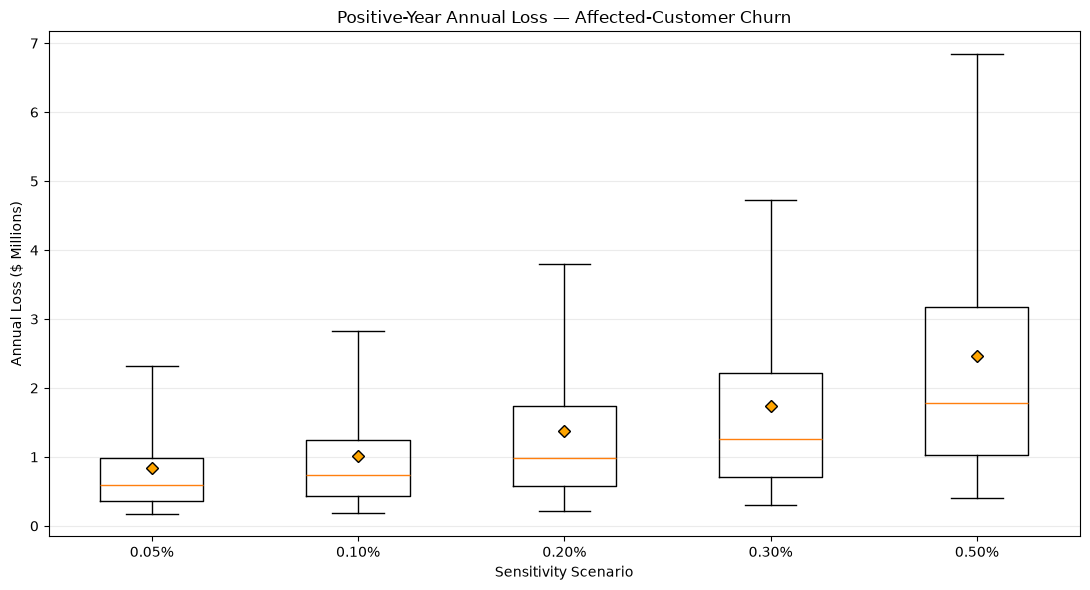

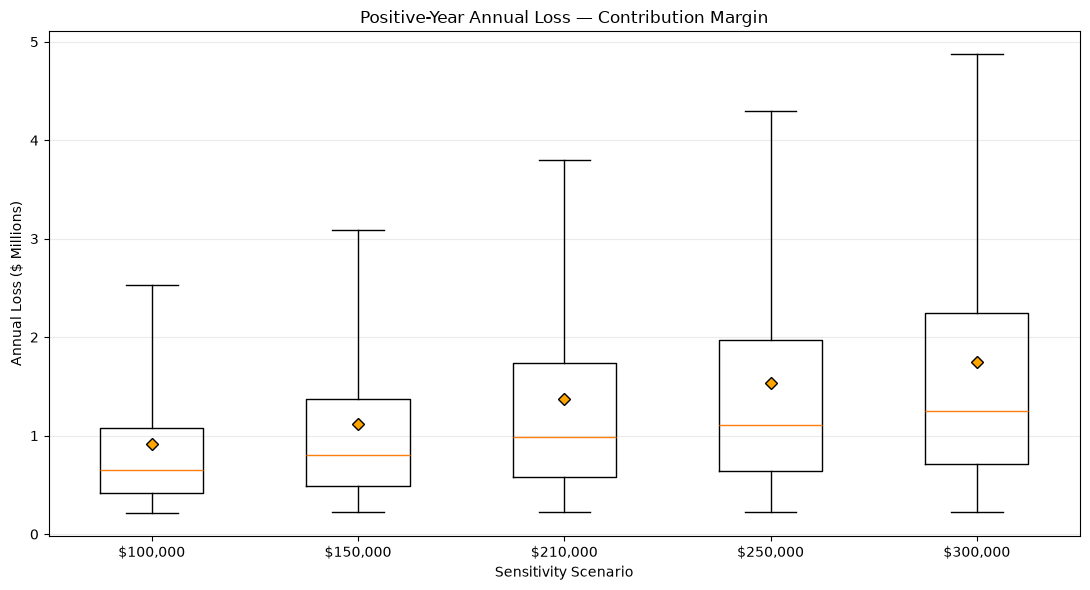

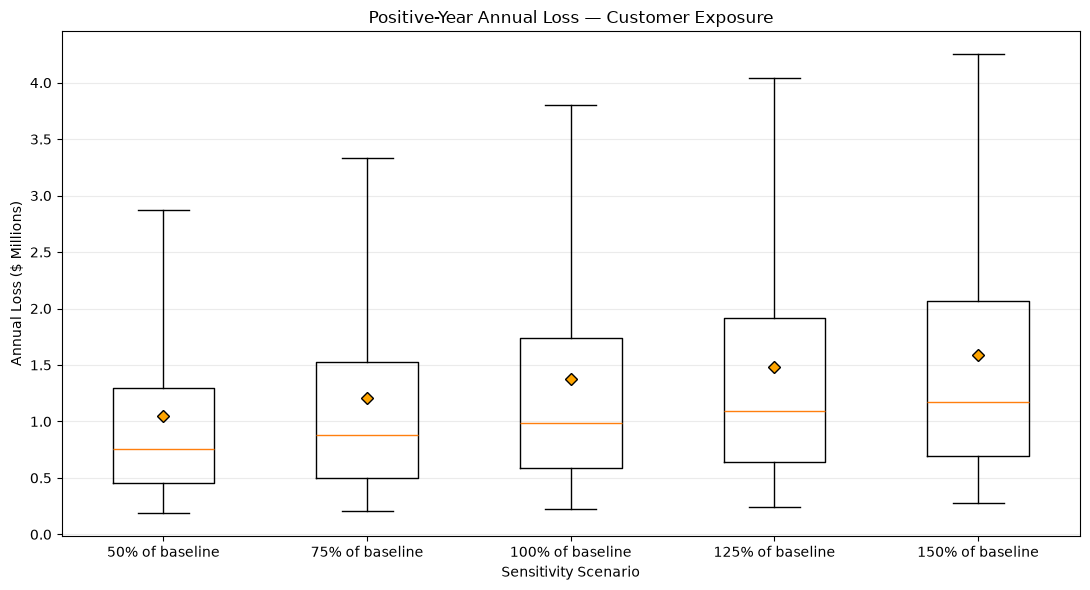

In [6]:
# Box-and-whisker plots

def plot_magnitude_boxplots(parameter):
    scenarios = sorted(
        [
            (key, annual)
            for key, annual in annual_losses_by_scenario.items()
            if key[0] == parameter
        ],
        key=lambda item: item[0][1],
    )

    data = []
    labels = []

    for (name, value), annual in scenarios:
        losses = annual["total_annual_loss_usd"].to_numpy()
        positive_losses = losses[losses > 0]

        data.append(positive_losses / 1e6)
        labels.append(scenario_label(parameter, value))

    fig, ax = plt.subplots(figsize=(11, 6))

    ax.boxplot(
        data,
        tick_labels=labels,
        whis=(5, 95),
        showmeans=True,
        showfliers=False,
        meanprops={
            "marker": "D",
            "markerfacecolor": "orange",
            "markeredgecolor": "black",
        },
    )

    ax.set_title(
        f"Positive-Year Annual Loss — {PARAMETER_LABELS[parameter]}"
    )
    ax.set_xlabel("Sensitivity Scenario")
    ax.set_ylabel("Annual Loss ($ Millions)")
    ax.grid(axis="y", alpha=0.25)

    plt.tight_layout()
    plt.show()


for parameter in PARAMETER_LABELS:
    plot_magnitude_boxplots(parameter)
